In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.io
import os
import pyvista as pv
import meshlib.mrmeshpy as mr
import meshlib.mrmeshnumpy as mrn
import math
import scipy

from alive_progress import alive_bar
from os import path

In [2]:
def filter_isolated_cells(array, struct):
    """ Return array with completely isolated single cells removed
    :param array: Array with completely isolated single cells
    :param struct: Structure array for generating unique regions
    :return: Array with minimum region size > 1
    """

    filtered_array = np.copy(array)
    id_regions, num_ids = scipy.ndimage.label(filtered_array, structure=struct)
    id_sizes = np.array(scipy.ndimage.sum(array, id_regions, np.linspace(0,num_ids,num_ids+1)))
    #print(np.linspace(0,num_ids,num_ids+1))
    #print(id_sizes)
    area_mask = (id_sizes == 1)
    filtered_array[area_mask[id_regions]] = 0
    return filtered_array

## Import .mat files

In [3]:
curpath=os.path.abspath(os.getcwd()).replace("\\","/")

In [4]:
os.chdir(curpath)
print(curpath)
completed=0

#os.chdir(os.getenv("HOME")+"/host_home/researcher/Physicell_COMMBINI_3D")
os.chdir("../output")

/config/researcher_home/Physicell_COMMBINI_3D/python


In [5]:
cellmat=scipy.io.loadmat('./XML and MAT files/new_output00000000_cells_physicell.mat')

### Preliminary view

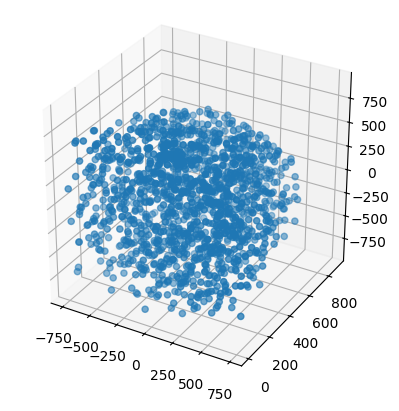

In [6]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

ind=np.where((cellmat['cells'][2,]>0.0))

ax.scatter(cellmat['cells'][1,ind], cellmat['cells'][2,ind], cellmat['cells'][3,ind], marker='o')
ax.set_box_aspect([1,1,1])

plt.show()

## Plot

#### Cortex and marrow

In [7]:
blocks_bone=pv.MultiBlock()
mesh_cor1=pv.CylinderStructured(radius=(500.0,650.0), height=500.0, center=(750.0,0.0,0.0), direction=(1.0,0.0,0.0))
mesh_mar1=pv.Cylinder(radius=(500.0), height=250.0, center=(875.5,0.0,0.0), direction=(1.0,0.0,0.0))
mesh_cor2=pv.CylinderStructured(radius=(500.0,650.0), height=500.0, center=(-750.0,0.0,0.0), direction=(1.0,0.0,0.0))
mesh_mar2=pv.Cylinder(radius=(500.0), height=250.0, center=(-875.5,0.0,0.0), direction=(1.0,0.0,0.0))

mesh_cor1.cell_data['bone_ID']=np.ones(mesh_cor1.n_cells)*1
mesh_cor2.cell_data['bone_ID']=np.ones(mesh_cor2.n_cells)*1
mesh_mar1.cell_data['bone_ID']=np.ones(mesh_mar1.n_cells)*2
mesh_mar2.cell_data['bone_ID']=np.ones(mesh_mar2.n_cells)*2

blocks_bone.append(mesh_cor1)
blocks_bone.append(mesh_mar1)
blocks_bone.append(mesh_cor2)
blocks_bone.append(mesh_mar2)

os.chdir(curpath)
blocks_bone.extract_geometry().save('Bone.vtk')

#### Cells

In [11]:
for t in range(24,25):
    tst=str(t)
    if t<100:
        tst='0'+tst
        if t<10:
            tst='0'+tst
            
    os.chdir("../output")
    cellmat=scipy.io.loadmat('./XML and MAT files/new_output00000' + tst +  '_cells_physicell.mat')

    print('ROUND '+tst)
        
    blocks_cell=pv.MultiBlock()
    blocks_nuclei=pv.MultiBlock()
    os.chdir(curpath)
    
    ncells=len(cellmat['cells'][1,])
    
    #with alive_bar(len(cellmat['cells'][1,]), force_tty=True) as bar:
    with alive_bar(ncells-1, force_tty=True) as bar:
        for c in range(1,ncells): #len(cellmat['cells'][1,])):
            if cellmat['cells'][2,c]>0.0:
                poscell=[cellmat['cells'][1,c],cellmat['cells'][2,c],cellmat['cells'][3,c]]
                volcell=cellmat['cells'][4,c]
                volnuc=cellmat['cells'][9,c]
                radcell=((3*volcell/4*math.pi)**(1.0/3.0))
                radnuc=((3*volnuc/4*math.pi)**(1.0/3.0))
                #print(radcell)
                
                mesh_cell = pv.Sphere(radius=radcell, center=(poscell[0],poscell[1],poscell[2]))
                #mesh_cell.decimate(target_reduction=0.8, inplace=True)
        
                mesh_cell.cell_data['cell_num']=np.ones(mesh_cell.n_cells)*c
                mesh_cell.cell_data['cell_ID']=np.ones(mesh_cell.n_cells)*cellmat['cells'][0,c]
                mesh_cell.cell_data['x']=np.ones(mesh_cell.n_cells)*poscell[0]
                mesh_cell.cell_data['y']=np.ones(mesh_cell.n_cells)*poscell[1]
                mesh_cell.cell_data['z']=np.ones(mesh_cell.n_cells)*poscell[2]
                mesh_cell.cell_data['cell_volume']=np.ones(mesh_cell.n_cells)*volcell
                mesh_cell.cell_data['cell_type']=np.ones(mesh_cell.n_cells)*cellmat['cells'][5,c]
        
                blocks_cell.append(mesh_cell)
                
                mesh_nuclei = pv.Sphere(radius=radnuc, center=(poscell[0],poscell[1],poscell[2]))
                #mesh_nuclei.decimate(target_reduction=0.8, inplace=True)
                
                blocks_nuclei.append(mesh_nuclei)
    
            bar()
    
    blocks_cell.extract_geometry().save('Cell_' + tst + '.vtk')
    blocks_nuclei.extract_geometry().save('Nuclei_' + tst + '.vtk')

ROUND 024
|████████████████████████████████████████| 147497/147497 [100%] in 44:30:51.8 (0 █▆▄ 4299/147497 [3%] in 1:02 (~34:16, █▆▄ 4826/147497 [3%] in 1:38 (~48:10, ▁▃▅ 6310/147497 [4%] in 3:30 (~1:18:0 █▆▄ 7077/147497 [5%] in 4:29 (~1:28:5 ▇▅▃ 7078/147497 [5%] in 4:29 (~1:28:5 ▇▇▅ 11953/147497 [8%] in 14:32 (~2:44 ▆█▆ 15499/147497 [11%] in 25:54 (~3:4 ▁▃▅ 15761/147497 [11%] in 26:57 (~3:4 ▅▇▇ 15771/147497 [11%] in 27:00 (~3:4 ▆█▆ 15956/147497 [11%] in 27:46 (~3:4 ▇▇▅ 15984/147497 [11%] in 27:51 (~3:4 ▂▄▆ 16504/147497 [11%] in 29:57 (~3:5 ▂▂▄ 17581/147497 [12%] in 34:23 (~4:1 ▃▁▃ 17859/147497 [12%] in 35:42 (~4:1 ▇▇▅ 18241/147497 [12%] in 37:22 (~4:2 ▇▅▃ 18242/147497 [12%] in 37:22 (~4:2 ▇▅▃ 19696/147497 [13%] in 44:06 (~4:4 ▂▄▆ 19868/147497 [13%] in 44:56 (~4:4 ▃▁▃ 22910/147497 [16%] in 1:01:18 (~5 ▅▇▇ 23073/147497 [16%] in 1:02:14 (~5 ▄▂▂ 23557/147497 [16%] in 1:05:06 (~5 ▂▂▄ 24000/147497 [16%] in 1:07:53 (~5 ▆█▆ 24231/147497 [16%] in 1:09:14 (~5 ▇▇▅ 24491/147497 [17%] in 1:10:49 (

#### Microenvironment

In [ ]:
filter_trig=True
for t in range(0,10):
    tst=str(t)
    if t<100:
        tst='0'+tst
        if t<10:
            tst='0'+tst

            os.chdir("../output")
            uenvmat=scipy.io.loadmat('./XML and MAT files/new_output00000' + tst +  '_microenvironment0.mat')
            #uenvmat=scipy.io.loadmat('./XML and MAT files/initial_microenvironment0.mat')
            
            xco=list(set(uenvmat['multiscale_microenvironment'][0,]))
            xco.sort()
            yco=list(set(uenvmat['multiscale_microenvironment'][1,]))
            yco.sort()
            zco=list(set(uenvmat['multiscale_microenvironment'][2,]))
            zco.sort()
            
            dx=xco[2]-xco[1]
            dy=yco[2]-yco[1]
            dz=yco[2]-yco[1]
            
            xmin=np.min(xco)-dx/2
            xmax=np.max(xco)+dx/2
            ymin=np.min(yco)-dy/2
            ymax=np.max(yco)+dy/2
            zmin=np.min(zco)-dz/2
            zmax=np.max(zco)+dz/2
            
            cytos=['Debris', 'TNFa', 'IL10'] 
            cytoind=[4,5,7]

            range_Debris=[1e-6, 1e-4]
            range_TNFa=[1e-16, 1e-12]
            range_IL10=[1e-17, 1e-13]
            
            # range_Debris=[-5, -4]
            # range_TNFa=[-15, -14]
            # range_IL10=[-16, -14]
            
            res=10
            
            for n,c in enumerate(cytos):
                globals()['blocks_'+ c]=pv.MultiBlock()
                
                globals()['mat_'+ c]=np.zeros((int((xmax-xmin)/dx),int((ymax-xmin)/dx),int((xmax-xmin)/dx)))
            
                globals()['space_' + c]=np.linspace(globals()['range_' + c][0],globals()['range_' + c][1],res)
                globals()['space_' + c]=np.geomspace(globals()['range_' + c][0],globals()['range_' + c][1],res)
                #globals()['space_' + c]=np.logspace(globals()['range_' + c][0],globals()['range_' + c][1],res)

            with alive_bar(math.prod(np.shape(globals()['mat_'+ c])), force_tty=True) as bar:
                for i, x in enumerate(xco):
                    for j, y in enumerate(yco):
                        for k, z in enumerate(zco):
                            bar()
                            ind=np.where(((uenvmat['multiscale_microenvironment'][0,]==x) & (uenvmat['multiscale_microenvironment'][1,]==y)) & (uenvmat['multiscale_microenvironment'][2,]==z))
                            for n,c in enumerate(cytos):
                                if(((uenvmat['multiscale_microenvironment'][cytoind[n],ind]/8000)>=globals()['space_' + c][0])&((uenvmat['multiscale_microenvironment'][cytoind[n],ind]/8000)<globals()['space_' + c][-1])):
                                    for p, v in enumerate(globals()['space_' + c]):
                                        if (((uenvmat['multiscale_microenvironment'][cytoind[n],ind]/8000)>=v)&((uenvmat['multiscale_microenvironment'][cytoind[n],ind]/8000)<globals()['space_' + c][p+1])):
                                            globals()['mat_' + c][i,j,k]=p+1
                                            break
                                elif ((uenvmat['multiscale_microenvironment'][cytoind[n],ind]/8000)>=globals()['space_' + c][-1]):
                                    globals()['mat_' + c][i,j,k]=res

            os.chdir(curpath)
            for n, c in enumerate(cytos): 
                globals()['blocks_'+ c]=pv.MultiBlock()
                
                for  p, v in enumerate(globals()['space_' + c]):
            
                    graph_array=(globals()['mat_' + c]==p+1)*1
                    if filter_trig & (np.max(globals()['mat_' + c]==p+1)>0):
                        filter_array = filter_isolated_cells(graph_array, struct=np.ones((3,3,3)))
                        #globals()['mat_' + c]=globals()['mat_' + c]*filter_array
                        graph_array=filter_array
                        #print(filter_array)
                         
                    simpleVolume = mrn.simpleVolumeFrom3Darray(np.float32(graph_array))
                    floatGrid = mr.simpleVolumeToDenseGrid(simpleVolume)
                    mesh_stl = mr.gridToMesh(floatGrid , mr.Vector3f(dx,dy,dz), 0.5)    
                    mr.saveMesh(mesh_stl,"part_uenv"+ str(p) + "_mesh.stl" )
                    
                    mesh_uenv = pv.read("part_uenv"+ str(p) + "_mesh.stl")
                    #mesh_uenv.decimate(target_reduction=0.8, inplace=True

                    #print(v)
                
                    mesh_uenv.cell_data[c]=np.ones(mesh_uenv.n_cells)*v
                    #mesh_uenv.cell_data['nu']=np.ones(mesh_uenv.n_cells)*(p+1)
                    mesh_uenv=mesh_uenv.translate((xmin,ymin,zmin),inplace=False)
                    globals()['blocks_'+ c].append(mesh_uenv)
            
                globals()['blocks_'+ c].extract_geometry().save(c + '_' + tst + '.vtk')                    

|████████████████████████████████████████| 1000000/1000000 [100%] in 34:53.8 (47
|████████████████████████████████████████| 1000000/1000000 [100%] in 35:20.7 (47
|████████████████████████████████████████| 1000000/1000000 [100%] in 35:39.5 (46
|█████████████████▏                      | ▇▇▅ 429036/1000000 [43%] in 15:22 (~2

In [ ]:
os.chdir(curpath)
filter_trig=False
for n, c in enumerate(cytos): 
    
    globals()['blocks_'+ c]=pv.MultiBlock()
    
    for  p, v in enumerate(globals()['space_' + c]):

        graph_array=(globals()['mat_' + c]==p+1)*1
        if filter_trig & (np.max(globals()['mat_' + c]==p+1)>0):
            filter_array = filter_isolated_cells(graph_array, struct=np.ones((3,3,3)))
            #globals()['mat_' + c]=globals()['mat_' + c]*filter_array
            graph_array=filter_array
            #print(filter_array)
             
        simpleVolume = mrn.simpleVolumeFrom3Darray(np.float32(graph_array))
        floatGrid = mr.simpleVolumeToDenseGrid(simpleVolume)
        mesh_stl = mr.gridToMesh(floatGrid , mr.Vector3f(dx,dy,dz), 0.5)    
        mr.saveMesh(mesh_stl,"part_uenv_mesh.stl" )
        
        mesh_uenv = pv.read("part_uenv_mesh.stl")
        #mesh_uenv.decimate(target_reduction=0.8, inplace=True

        print(v)
        mesh_uenv.cell_data[c]=np.ones(mesh_uenv.n_cells)*v
        mesh_uenv=mesh_uenv.translate((xmin,ymin,zmin),inplace=False)
        globals()['blocks_'+ c].append(mesh_uenv)

    globals()['blocks_'+ c].extract_geometry().save(c + '_' + tst + '.vtk')        

### v2


In [ ]:
tst='001'

os.chdir("../output")
uenvmat=scipy.io.loadmat('./XML and MAT files/new_output00000' + tst +  '_microenvironment0.mat')

xco=list(set(uenvmat['multiscale_microenvironment'][0,]))
xco.sort()
yco=list(set(uenvmat['multiscale_microenvironment'][1,]))
yco.sort()
zco=list(set(uenvmat['multiscale_microenvironment'][2,]))
zco.sort()

dx=xco[2]-xco[1]
dy=yco[2]-yco[1]
dz=yco[2]-yco[1]
print(dx)
blocks_uenv=pv.MultiBlock()

with alive_bar(64000, force_tty=True) as bar:
    for i in xco:
        for j in yco:
            for k in zco:
                bar()
                ind=np.where(((uenvmat['multiscale_microenvironment'][0,]==i) & (uenvmat['multiscale_microenvironment'][1,]==j)) & (uenvmat['multiscale_microenvironment'][2,]==k))
                if uenvmat['multiscale_microenvironment'][5,ind[0]]>1e-14:
                    mesh_uenv = pv.Cube(center=(i,j,k),x_length=dx, y_length=dy, z_length=dz)
                    #print(ind[0])
                    mesh_uenv.cell_data['TNFa']=np.ones(mesh_uenv.n_cells)*uenvmat['multiscale_microenvironment'][5,ind[0]]
                    
                    blocks_uenv.append(mesh_uenv)
            
os.chdir(curpath)
blocks_uenv.extract_geometry().save('Debris_' + tst + '.vtk')
            

In [ ]:
os.chdir(curpath)
blocks_uenv.extract_geometry().save('Debris_' + tst + '.vtk')

## SANDBOX

In [ ]:
import random

xc=[0, random.uniform(20,40), random.uniform(20,40), random.uniform(20,40), -random.uniform(20,40), -random.uniform(20,40)]
yc=[0, -random.uniform(20,40), random.uniform(20,40), -random.uniform(20,40), -random.uniform(20,40)]
zc=[0, random.uniform(20,40), -random.uniform(20,40), -random.uniform(20,40), -random.uniform(20,40)]

rc=[15, 6, 6, 6, 6]
rn=[10, 3, 3, 3, 3]

blocks_cell=pv.MultiBlock()
blocks_nuclei=pv.MultiBlock()

for i in range(0,5):

    mesh_cell = pv.Sphere(radius=rc[i], center=(xc[i],yc[i],zc[i]))
    mesh_cell.decimate(target_reduction=0.8, inplace=True)

    blocks_cell.append(mesh_cell)

    if i>0:
        mesh_nuclei = pv.Sphere(radius=rn[i], center=(xc[i],yc[i],zc[i]))
        mesh_nuclei.decimate(target_reduction=0.8, inplace=True)
    
        blocks_nuclei.append(mesh_nuclei)
    else:
        blocks_cell.extract_geometry().save('Blob_test.vtk')
        blocks_cell=pv.MultiBlock()

blocks_cell.extract_geometry().save('Cell_test.vtk')
blocks_nuclei.extract_geometry().save('Nuclei_test.vtk')


In [ ]:
#mev=np.zeros((100,100,100))
blocks_uenv=pv.MultiBlock()

for x in range(-51,51,5):
    for y in range(-51,51,5):
        for z in range(-51,51,5):
            val_1=100/((x**2+y**2+z**2)+1)
            val_2=0
            for p in range(1,5):
                val_1-=10/(((x-xc[p])**2+(y-yc[p])**2+(z-zc[p])**2)+1)
                val_2+=10/(((x-xc[p])**2+(y-yc[p])**2+(z-zc[p])**2)+1)
            mesh_uenv = pv.Cube(center=(x,y,z),x_length=5, y_length=5, z_length=5)
            #print(ind[0])
            mesh_uenv.cell_data['TNFa']=np.ones(mesh_uenv.n_cells)*val_1
            mesh_uenv.cell_data['IL10']=np.ones(mesh_uenv.n_cells)*val_2
            
            blocks_uenv.append(mesh_uenv)

blocks_uenv.extract_geometry().save('Debris_test.vtk')

In [ ]:
blocks_uenv.extract_geometry().save('Debris_test.vtk')